**Descripción de la actividad**

El conjunto de datos con el cual va a trabajar tiene por nombre `creditcardcsvpresent.csv` y se encuentra en el siguiente [link](https://www.kaggle.com/shubhamjoshi2130of/abstract-data-set-for-credit-card-fraud-detection).

De este conjunto de dato deberá realizar las siguientes actividades:

1. **Análisis descriptivo de los datos.**

*   De las variables numéricas, hallar datos estadísticos.
*   De las variables categóricas, hallar la lista de las diferentes categorías y hallar la frecuencia de cada una de ellas.
*   Crear la matriz de correlaciones existentes entre las variables numéricas del conjunto de datos y **analizar los resultados**.

2.  **Tratamiento de datos faltantes.**

*   Si existen valores faltantes, decidir si eliminar los registros o llenarlos con valores como la media, la mediana o la moda. **Justificar la respuesta**.

3.  **Agrupamiento con K-means.**

*   Aplique la técnica del codo y obtenga la gráfica característica. Una vez obtenida, analícela y, según su criterio, deduzca el número de clusters ideal.
*   Crear 3 modelos diferentes con 2, 3 y 4 clusters utilizando la técnica K-means con los siguientes hiperparámetros `max_iter = 1000` y `random_state=0` de la siguiente forma:

`KMeans(n_clusters=el_número_de_clusters, max_iter=1000, random_state=0)`

4.  **Análisis de resultados.**

*   Para cada uno de los modelos obtenidos debe graficar los clusters creados y obtener sus valores de exactitud (`accuracy`). Un ejemplo de la gráfica la puede observar en la imagen abajo.
*   Analice estos valores de exactitud, compárelos entre ellos y deduzca cuál es el que tiene mayor exactitud. Este le dirá el número de clusters ideal. **¿Concuerda con el valor que escogió al utilizar la técnica del codo?**
*   Agregue las conclusiones que considere pertinentes.

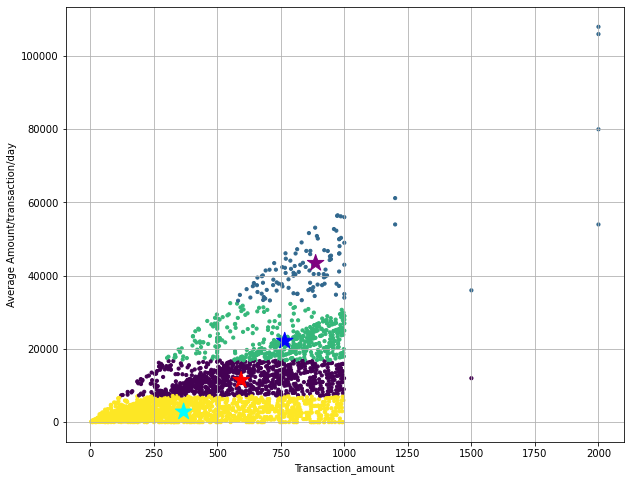

In [21]:
# Librerías para descargar de Kaggle y para ver archivos
import kagglehub
import os

# Descargamos el dataset
path = kagglehub.dataset_download("shubhamjoshi2130of/abstract-data-set-for-credit-card-fraud-detection")

print("Carpeta:", path)
print("Archivos:", os.listdir(path))

Using Colab cache for faster access to the 'abstract-data-set-for-credit-card-fraud-detection' dataset.
Carpeta: /kaggle/input/abstract-data-set-for-credit-card-fraud-detection
Archivos: ['creditcardcsvpresent.csv']


In [22]:
# Librería para manejar tablas de datos
import pandas as pd

# Abrimos el CSV
df = pd.read_csv(os.path.join(path, 'creditcardcsvpresent.csv'))

# Cambiamos los nombres de las columnas a español
df = df.rename(columns={
    'Merchant_id': 'id_comercio',
    'Transaction date': 'fecha_transaccion',
    'Average Amount/transaction/day': 'monto_promedio_dia',
    'Transaction_amount': 'monto_transaccion',
    'Is declined': 'rechazada',
    'Total Number of declines/day': 'rechazos_dia',
    'isForeignTransaction': 'transaccion_extranjera',
    'isHighRiskCountry': 'pais_alto_riesgo',
    'Daily_chargeback_avg_amt': 'contracargo_prom_dia',
    '6_month_avg_chbk_amt': 'contracargo_prom_6meses',
    '6-month_chbk_freq': 'frecuencia_contracargo_6meses',
    'isFradulent': 'fraude'
})

print("Tamaño:", df.shape)
df.head()

Tamaño: (3075, 12)


,id_comercio,fecha_transaccion,monto_promedio_dia,monto_transaccion,rechazada,rechazos_dia,transaccion_extranjera,pais_alto_riesgo,contracargo_prom_dia,contracargo_prom_6meses,frecuencia_contracargo_6meses,fraude
0,3160040998,NaN,100.0,3000.0,N,5,Y,Y,0,0.0,0,Y
1,3160040998,NaN,100.0,4300.0,N,5,Y,Y,0,0.0,0,Y
2,3160041896,NaN,185.5,4823.0,Y,5,N,N,0,0.0,0,Y
3,3160141996,NaN,185.5,5008.5,Y,8,N,N,0,0.0,0,Y
4,3160241992,NaN,500.0,26000.0,N,0,Y,Y,800,677.2,6,Y


## 1. Análisis descriptivo de los datos

### 1.1 Estadísticas de las variables numéricas

Se excluyen id_comercio, porque es un código que identifica al comercio y no una cantidad, y fecha_transaccion, porque está vacía.

In [23]:
# Información general: tipo de dato y cantidad de valores no vacíos por columna
df.info()

# Estadísticas descriptivas de las variables numéricas
df.drop(columns=['id_comercio', 'fecha_transaccion']).describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3075 entries, 0 to 3074
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_comercio                    3075 non-null   int64  
 1   fecha_transaccion              0 non-null      float64
 2   monto_promedio_dia             3075 non-null   float64
 3   monto_transaccion              3075 non-null   float64
 4   rechazada                      3075 non-null   object 
 5   rechazos_dia                   3075 non-null   int64  
 6   transaccion_extranjera         3075 non-null   object 
 7   pais_alto_riesgo               3075 non-null   object 
 8   contracargo_prom_dia           3075 non-null   int64  
 9   contracargo_prom_6meses        3075 non-null   float64
 10  frecuencia_contracargo_6meses  3075 non-null   int64  
 11  fraude                         3075 non-null   object 
dtypes: float64(4), int64(4), object(4)
memory usage:

,monto_promedio_dia,monto_transaccion,rechazos_dia,contracargo_prom_dia,contracargo_prom_6meses,frecuencia_contracargo_6meses
count,3075.000000,3075.000000,3075.000000,3075.000000,3075.000000,3075.000000
mean,515.026556,9876.399210,0.957398,55.737561,40.022407,0.391870
std,291.906978,10135.331016,2.192391,206.634779,155.968840,1.548479
min,4.011527,0.000000,0.000000,0.000000,0.000000,0.000000
25%,269.788047,2408.781147,0.000000,0.000000,0.000000,0.000000
50%,502.549575,6698.891856,0.000000,0.000000,0.000000,0.000000
75%,765.272803,14422.568935,0.000000,0.000000,0.000000,0.000000
max,2000.000000,108000.000000,20.000000,998.000000,998.000000,9.000000


Análisis:

El conjunto tiene 3075 registros y 12 columnas. Todas están completas excepto fecha_transaccion, que está vacía.

En monto_promedio_dia la media (515) y la mediana (502) son parecidas, así que los datos están equilibrados. En monto_transaccion la media (9876) es mayor que la mediana (6699) y el máximo es 108000, lo que indica que hay pocas transacciones muy altas que suben el promedio.

En las variables de rechazos y contracargos la mediana y el percentil 75 son 0, es decir, la mayoría de las transacciones no tiene rechazos ni contracargos.


### 1.2 Variables categóricas

Las variables categóricas son rechazada, transaccion_extranjera, pais_alto_riesgo y fraude. Para cada una se muestran sus categorías y la frecuencia de cada una.

In [24]:
# Lista de las variables categóricas
categoricas = ['rechazada', 'transaccion_extranjera', 'pais_alto_riesgo', 'fraude']

# Para cada variable mostramos sus categorías y cuántas veces aparece cada una
for col in categoricas:
    print(col,'-categorías:', df[col].unique())
    display(df[col].value_counts().to_frame('frecuencia'))

rechazada -categorías: ['N' 'Y']


,frecuencia
rechazada,
N,3018
Y,57


transaccion_extranjera -categorías: ['Y' 'N']


,frecuencia
transaccion_extranjera,
N,2369
Y,706


pais_alto_riesgo -categorías: ['Y' 'N']


,frecuencia
pais_alto_riesgo,
N,2870
Y,205


fraude -categorías: ['Y' 'N']


,frecuencia
fraude,
N,2627
Y,448


Análisis:

Las cuatro variables categóricas tienen solo dos categorías: Y (sí) y N (no). En todas predomina la N.

Solo 57 transacciones fueron rechazadas (1.9%), 706 fueron extranjeras (23%) y 205 vinieron de países de alto riesgo (6.7%). En fraude hay 448 casos (14.6%) frente a 2627 transacciones normales, por lo que los datos están desbalanceados: hay muchas más transacciones normales que fraudulentas.

### 1.3 Matriz de correlación

Se calcula la correlación entre las variables numéricas para ver cuáles se relacionan entre sí.

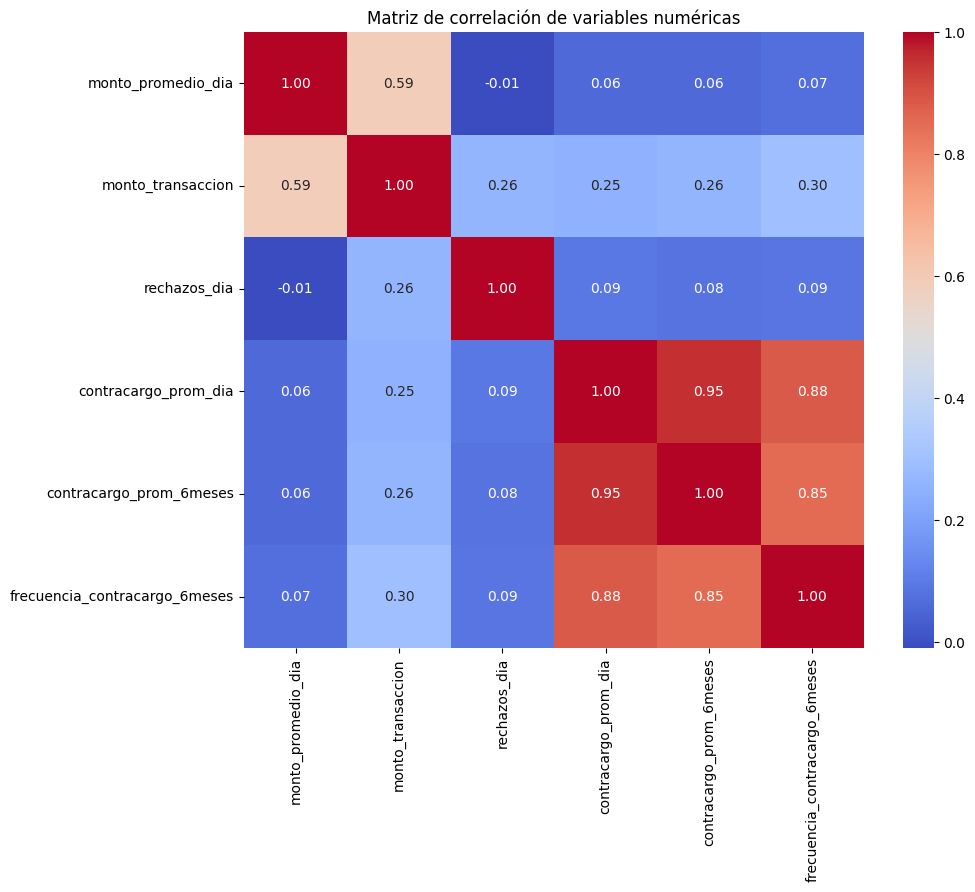

In [25]:
# Librerías para graficar
import matplotlib.pyplot as plt
import seaborn as sns

# Tomamos solo las variables numéricas (sin id_comercio ni fecha_transaccion)
numericas = df.select_dtypes(include='number').drop(columns=['id_comercio', 'fecha_transaccion'])

# Calculamos la matriz de correlación
correlacion = numericas.corr()

# La graficamos como un mapa de calor
plt.figure(figsize=(10, 8))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de correlación de variables numéricas')
plt.show()

Análisis:

Las variables de contracargo (contracargo_prom_dia, contracargo_prom_6meses y frecuencia_contracargo_6meses) tienen una correlación muy alta entre sí (0.85 a 0.95), ya que miden información muy parecida: un comercio con muchos contracargos en un día también los tiene en seis meses.

monto_promedio_dia y monto_transaccion tienen una correlación moderada (0.59): cuando el promedio diario es alto, el monto de la transacción también tiende a serlo. monto_transaccion tiene una relación débil con las variables de contracargo (0.25 a 0.30).

rechazos_dia casi no se relaciona con las demás variables (valores cercanos a 0), y no hay correlaciones negativas importantes.

## 2. Tratamiento de datos faltantes

In [26]:
print('Valores faltantes por columna:')
print(df.isnull().sum())

# Eliminamos la columna fecha_transaccion porque está completamente vacía
df = df.drop(columns=['fecha_transaccion'])

print('\nTotal de faltantes después del tratamiento:', df.isnull().sum().sum())
print('Tamaño final:', df.shape)

Valores faltantes por columna:
id_comercio                         0
fecha_transaccion                3075
monto_promedio_dia                  0
monto_transaccion                   0
rechazada                           0
rechazos_dia                        0
transaccion_extranjera              0
pais_alto_riesgo                    0
contracargo_prom_dia                0
contracargo_prom_6meses             0
frecuencia_contracargo_6meses       0
fraude                              0
dtype: int64

Total de faltantes después del tratamiento: 0
Tamaño final: (3075, 11)


Justificación:

La única columna con valores faltantes es fecha_transaccion, que está vacía en los 3075 registros. Se decidió eliminar la columna completa y no los registros, porque al borrar las filas con faltantes se perderían todos los datos.

Tampoco es posible llenarla con la media, la mediana o la moda, porque no hay ningún valor a partir del cual calcularlas. Las demás columnas no tienen faltantes, así que el conjunto final queda con 3075 registros y 11 columnas.

## 3. Agrupamiento con K-means

Para el agrupamiento se usan las seis variables numéricas: monto_promedio_dia, monto_transaccion, rechazos_dia, contracargo_prom_dia, contracargo_prom_6meses y frecuencia_contracargo_6meses. No se usa id_comercio porque es un código, ni las variables categóricas, porque K-means trabaja con distancias entre números.

### 3.1 Método del codo

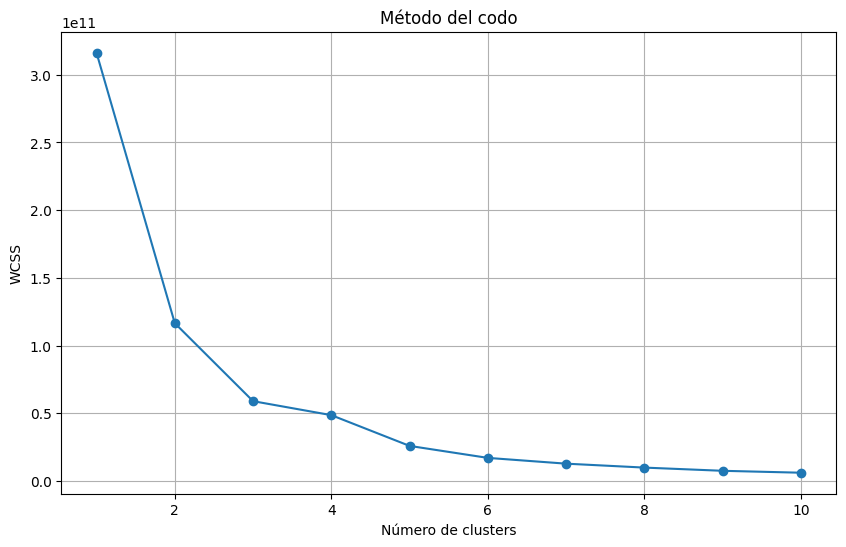

In [27]:
# Librería para el agrupamiento
from sklearn.cluster import KMeans

# Variables que usaremos para agrupar
X = df[['monto_promedio_dia', 'monto_transaccion', 'rechazos_dia',
        'contracargo_prom_dia', 'contracargo_prom_6meses', 'frecuencia_contracargo_6meses']]

# Calculamos el WCSS para 1 a 10 clusters
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, max_iter=1000, random_state=0)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Graficamos el método del codo
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Método del codo')
plt.xlabel('Número de clusters')
plt.ylabel('WCSS')
plt.grid()
plt.show()

Análisis:

El WCSS baja mucho al pasar de 1 a 2 clusters y también de 2 a 3, donde se reduce casi a la mitad. A partir de 3 clusters la curva baja muy poco y se va aplanando, es decir, agregar más grupos casi no mejora el agrupamiento. Por eso se escogió K = 3 como el número de clusters ideal según el método del codo.

### 3.2 Modelos con 2, 3 y 4 clusters

In [28]:
# Modelo con 2 clusters
modelo_2 = KMeans(n_clusters=2, max_iter=1000, random_state=0)
etiquetas_2 = modelo_2.fit_predict(X)

# Modelo con 3 clusters
modelo_3 = KMeans(n_clusters=3, max_iter=1000, random_state=0)
etiquetas_3 = modelo_3.fit_predict(X)

# Modelo con 4 clusters
modelo_4 = KMeans(n_clusters=4, max_iter=1000, random_state=0)
etiquetas_4 = modelo_4.fit_predict(X)

# Cantidad de transacciones en cada cluster
print('2 clusters:', pd.Series(etiquetas_2).value_counts().sort_index().tolist())
print('3 clusters:', pd.Series(etiquetas_3).value_counts().sort_index().tolist())
print('4 clusters:', pd.Series(etiquetas_4).value_counts().sort_index().tolist())

2 clusters: [760, 2315]
3 clusters: [952, 1984, 139]
4 clusters: [973, 1934, 3, 165]


In [29]:
# Copiamos las variables y agregamos el cluster de cada transacción
grupos = X.copy()
grupos['cluster'] = etiquetas_3

# Porcentaje de fraude en cada transacción (1 si es fraude, 0 si no)
grupos['fraude_%'] = (df['fraude'] == 'Y') * 100

# Promedio de cada variable por cluster y cantidad de transacciones
resumen = grupos.groupby('cluster').mean().round(1)
resumen['cantidad'] = grupos['cluster'].value_counts().sort_index()
resumen

,monto_promedio_dia,monto_transaccion,rechazos_dia,contracargo_prom_dia,contracargo_prom_6meses,frecuencia_contracargo_6meses,fraude_%,cantidad
cluster,,,,,,,,
0,700.2,17507.1,1.2,87.9,63.9,0.6,22.3,952
1,402.2,4038.2,0.7,27.8,18.5,0.2,5.1,1984
2,858.0,40944.9,3.3,234.5,183.5,2.1,96.4,139


Análisis:

Con 2 clusters los datos se dividen en grupos de 760 y 2315 transacciones, y con 3 clusters en grupos de 952, 1984 y 139. Con 4 clusters la división es casi igual a la de 3, pero aparece un grupo de solo 3 transacciones con montos atípicos, por lo que un cuarto cluster no aporta un grupo significativo.

Al revisar el modelo de 3 clusters se observa que cada grupo tiene un perfil distinto. El cluster 1 (1984 transacciones) tiene montos bajos, pocos rechazos y contracargos, y solo 5.1% de fraude, es decir, son transacciones normales. El cluster 0 (952) tiene montos medios y 22.3% de fraude, por lo que es un grupo de riesgo intermedio. El cluster 2 (139) tiene los montos más altos, más rechazos y contracargos, y 96.4% de fraude.

Aunque K-means no usó la variable fraude, logró formar un grupo con casi solo transacciones fraudulentas, lo que indica que los fraudes comparten características: montos altos, más rechazos y más contracargos.

## 4. Análisis de resultados

### 4.1 Gráficas de los clusters

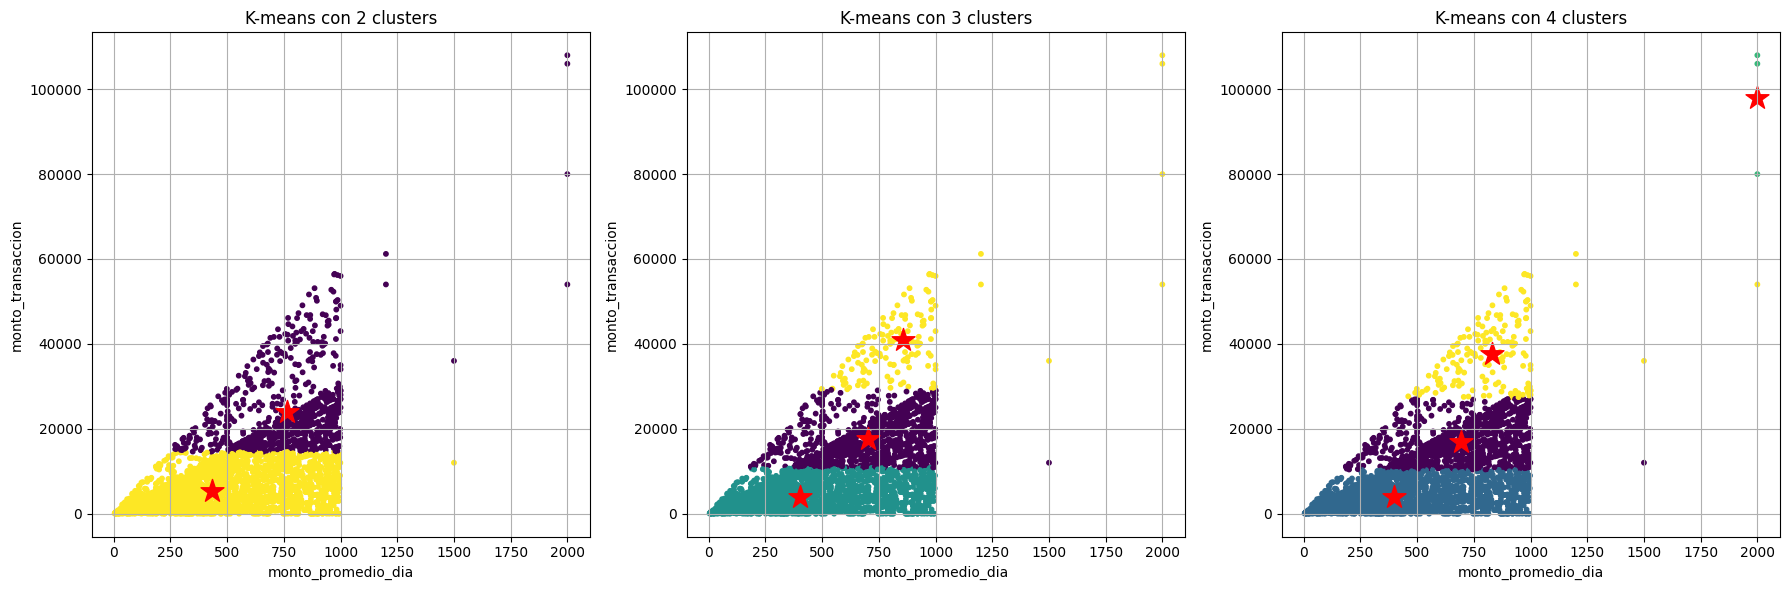

In [30]:
# Modelos y etiquetas que vamos a graficar
modelos = [(2, modelo_2, etiquetas_2), (3, modelo_3, etiquetas_3), (4, modelo_4, etiquetas_4)]

# Una sola figura con 3 gráficas lado a lado
fig, ejes = plt.subplots(1, 3, figsize=(18, 6))

for eje, (k, modelo, etiquetas) in zip(ejes, modelos):
    centroides = modelo.cluster_centers_
    # Puntos: cada color es un cluster
    eje.scatter(X['monto_promedio_dia'], X['monto_transaccion'], c=etiquetas, s=10)
    # Centroides: estrellas rojas
    eje.scatter(centroides[:, 0], centroides[:, 1], marker='*', c='red', s=300)
    eje.set_title(f'K-means con {k} clusters')
    eje.set_xlabel('monto_promedio_dia')
    eje.set_ylabel('monto_transaccion')
    eje.grid()

plt.tight_layout()
plt.show()

Análisis:

En los tres modelos los clusters forman franjas horizontales, es decir, se separan principalmente por monto_transaccion. Esto ocurre porque esta variable tiene valores mucho más grandes que las demás y, como K-means agrupa por distancias, es la que más influye.

### 4.2 Exactitud de los modelos

Como en clase, la exactitud se mide con el índice Rand ajustado (adjusted_rand_score), comparando los clusters de cada modelo con la variable fraude.

In [31]:
# Librería para medir la exactitud del agrupamiento
from sklearn.metrics import adjusted_rand_score

# Calculamos la exactitud de cada modelo comparando con la variable fraude
exactitud = pd.DataFrame({
    'clusters': [2, 3, 4],
    'exactitud': [
        adjusted_rand_score(df['fraude'], etiquetas_2),
        adjusted_rand_score(df['fraude'], etiquetas_3),
        adjusted_rand_score(df['fraude'], etiquetas_4)
    ]
})
exactitud

,clusters,exactitud
0,2,0.277334
1,3,0.219269
2,4,0.213517


Análisis:

El modelo con mayor exactitud es el de 2 clusters (0.277), seguido del de 3 (0.219) y el de 4 (0.214). Por lo tanto, según la exactitud el número ideal es 2, lo que no concuerda con el método del codo, que indicó 3.

Esto se explica porque la variable fraude solo tiene dos categorías, por lo que un modelo de dos grupos se ajusta mejor a ella. El método del codo, en cambio, busca los grupos más compactos sin tener en cuenta el fraude.

En los tres modelos la exactitud es baja, lo que indica que los clusters no separan completamente las transacciones fraudulentas de las normales, ya que el agrupamiento depende sobre todo del monto de la transacción.

## Conclusiones

- El conjunto de datos estaba casi completo; solo fue necesario eliminar fecha_transaccion por estar vacía. La variable fraude está desbalanceada, ya que solo el 14.6% de las transacciones son fraudulentas.

- El método del codo y la exactitud no coinciden en el número ideal de clusters (3 y 2, respectivamente) porque miden cosas distintas: el codo busca grupos compactos y la exactitud compara los grupos con la variable fraude, que tiene solo dos categorías.

- Aunque la exactitud del modelo de 3 clusters es baja, este modelo formó un grupo con 96.4% de fraude. Esto muestra que K-means puede ayudar a identificar transacciones de alto riesgo sin conocer previamente cuáles son fraudulentas.

- El agrupamiento depende sobre todo de monto_transaccion, porque sus valores son mucho más grandes que los de las otras variables. Para mejorar el modelo se podrían escalar las variables, de modo que todas tengan el mismo peso.